## mlpi26_Lect11_nbsup1.ipynb

# Transformers and attention for machine signals
### Lecture companion notebook — *Machine Learning with PyTorch and Scikit-Learn*, Chapter 16

This notebook continues the **CNC turning-cell** example from the Chapter 15 (RNN) lecture. A hard
inclusion near the start of a cycle chips the tool edge (the part comes out **undersize**); a heavy
finishing pass near the end deflects the tool (**oversize**). When both happen the errors cancel. To
classify the finished diameter, a model has to connect two events that are 50–100 samples apart —
exactly the long-range dependency that made the vanilla RNN fail last week.

**Learning objectives.** By the end you should be able to:

1. compute self-attention by hand — first with no parameters, then with query/key/value projections — and explain the $1/\sqrt{d_k}$ scaling with a measurement;
2. implement multi-head attention from scratch and verify it against `nn.MultiheadAttention`;
3. explain the parts of a transformer block (residuals, LayerNorm, feed-forward, Pre-LN vs Post-LN) and what a causal mask does;
4. show that self-attention cannot see order without positional information, and fix it;
5. turn a sensor time series into tokens by **patching**, and reason about the quadratic cost of attention;
6. pre-train a transformer on **unlabeled** machine cycles and use it when only a few labelled parts exist;
7. place BERT, GPT and BART-style models in one picture, and know what has changed in large language models since the book was written;
8. read an attention map critically — and check it with occlusion.

**Prerequisites:** the Chapter 15 lecture (RNNs, LSTM, padding), PyTorch `nn.Module` and training loops.

### What was kept, updated or dropped from the chapter

| Book section | Here |
|---|---|
| Attention for RNNs (Bahdanau) | kept briefly, as the historical motivation |
| Self-attention, scaled dot-product, Q/K/V | **kept, in full**, computed by hand on CNC data |
| Original transformer, multi-head attention, masking, positional encoding, LayerNorm | **kept**, plus the Pre-LN variant that modern models use |
| GPT-1/2/3 table, GPT-2 text generation with `transformers==4.9.1` | **replaced** — the version pin is years old and the table stops at 2020; §11 gives an updated landscape |
| BERT's next-sentence prediction | mentioned only — later models (RoBERTa) dropped it |
| Fine-tuning DistilBERT on IMDb | the *idea* (pre-train → adapt with few labels) is reproduced on machine data in §12; a modern Hugging Face recipe for **maintenance-log text** is given in §13 to run on your own machine |
| *New:* patching for time series, attention as explanation | added for engineering data |

In [1]:
import sys, time, json, platform
import numpy as np, torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt, matplotlib
import sklearn
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

torch.set_num_threads(2)
print("python", platform.python_version(), "| torch", torch.__version__, "| sklearn", sklearn.__version__,
      "| numpy", np.__version__)

BLUE, ORANGE, AQUA, YELLOW, RED, VIOLET, MUTED = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e34948", "#4a3aa7", "#898781"
plt.rcParams.update({"axes.grid": True, "grid.color": "#e1e0d9", "axes.spines.top": False,
                     "axes.spines.right": False, "legend.frameon": False, "figure.dpi": 100})

python 3.13.16 | torch 2.14.1+cu130 | sklearn 1.9.1 | numpy 2.5.3


## 1. The data: one CNC cycle per part

Each cycle is sampled at 50 Hz and lasts 110–150 samples. Four analogue channels — spindle current (A),
vibration RMS (g), spindle temperature (°C), feed rate — plus the G-code **op code** (approach, rough,
dwell, finish, retract). The generator is identical to last week's:

* a **hard inclusion** at $t\approx 25$ raises current *and* vibration for 3 samples → $-21\,\mu$m;
* a **heavy finishing pass** raises the finish-phase load → $+21\,\mu$m;
* 1–3 harmless **coolant surges** raise current only (a distractor);
* label = sign of the diameter error with a $\pm 12\,\mu$m tolerance: undersize / in tolerance / oversize.

| | light finish | heavy finish |
|---|---|---|
| **no inclusion** | in tolerance | oversize |
| **inclusion** | undersize | in tolerance (errors cancel) |

In [2]:
PHASES = ["approach", "rough", "dwell", "finish", "retract"]
FRAC = [0.09, 0.40, 0.05, 0.34, 0.12]
LEVEL = {"approach": (2.0, 0.25, 0.60), "rough": (12.0, 1.60, 0.80),     # current A, vibration g, feed
         "dwell": (4.0, 0.35, 0.00), "finish": (7.0, 0.90, 0.25), "retract": (2.0, 0.20, 0.90)}
FINISH_HEAVY = (8.6, 1.15, 0.30)
CHIP_UM, DEFL_UM, SIGMA_UM, TOL_UM = 21.0, 21.0, 4.0, 12.0
CLASSES = ["undersize", "in tolerance", "oversize"]
T_MAX, PATCH = 150, 10

def make_cycle(rng, chip, heavy):
    T = int(rng.integers(110, 151))
    bounds = np.round(np.cumsum([0] + FRAC) * T).astype(int)
    X = np.zeros((T, 4), np.float32); op = np.zeros(T, np.int64)
    for k, ph in enumerate(PHASES):
        a, b = bounds[k], bounds[k + 1]
        lv = FINISH_HEAVY if (ph == "finish" and heavy) else LEVEL[ph]
        X[a:b, 0] = lv[0]; X[a:b, 1] = lv[1]; X[a:b, 3] = lv[2]; op[a:b] = k
    X[:, 2] = 24 + 14 * (1 - np.exp(-np.arange(T) / 60))                # spindle warms up
    X[:, 0] += rng.normal(0, 0.35, T); X[:, 1] += rng.normal(0, 0.08, T)
    X[:, 2] += rng.normal(0, 0.15, T); X[:, 3] += rng.normal(0, 0.02, T)
    meta = {"surges": [], "t_chip": None, "bounds": bounds}
    for _ in range(int(rng.integers(1, 4))):                                # benign coolant surges
        t0 = int(rng.integers(bounds[1], bounds[4] - 3)); meta["surges"].append(t0)
        X[t0:t0 + 3, 0] += rng.uniform(2.0, 3.5); X[t0:t0 + 3, 1] += rng.uniform(0, 0.22)
    if chip:                                                                # hard inclusion, t ~ 25
        t0 = int(rng.integers(20, 31)); meta["t_chip"] = t0
        X[t0:t0 + 3, 0] += rng.uniform(2.0, 3.5); X[t0:t0 + 3, 1] += rng.uniform(2.4, 3.2)
    delta = -CHIP_UM * chip + DEFL_UM * heavy + rng.normal(0, SIGMA_UM)
    y = 0 if delta < -TOL_UM else (2 if delta > TOL_UM else 1)
    return X, op, y, meta

def make_dataset(n, seed):
    rng = np.random.default_rng(seed); out = []
    for _ in range(n):
        chip, heavy = int(rng.random() < .5), int(rng.random() < .5)
        X, op, y, meta = make_cycle(rng, chip, heavy)
        out.append((X, op, y, chip, heavy, meta))
    return out

MU = np.array([7.0, 0.95, 33.0, 0.5], np.float32); SD = np.array([4.0, 0.8, 4.5, 0.32], np.float32)

def to_tensors(data):
    '''Pad to T_MAX; per-sample features = 4 standardised channels + one-hot op code (9).'''
    n = len(data); Fe = np.zeros((n, T_MAX, 9), np.float32)
    L = np.zeros(n, np.int64); y = np.zeros(n, np.int64)
    for i, (X, op, yy, *_ ) in enumerate(data):
        T = len(X); Fe[i, :T, :4] = (X - MU) / SD; Fe[i, np.arange(T), 4 + op] = 1
        L[i] = T; y[i] = yy
    return torch.tensor(Fe), torch.tensor(L), torch.tensor(y)

dtr, dva, dte = make_dataset(800, 7), make_dataset(300, 108), make_dataset(600, 209)
tr, va, te = to_tensors(dtr), to_tensors(dva), to_tensors(dte)
print("train/valid/test:", len(dtr), len(dva), len(dte), "| tensor shape", tuple(tr[0].shape))
print("test class balance:", dict(zip(CLASSES, np.round(np.bincount(te[2].numpy()) / len(te[2]), 3))))

train/valid/test: 800 300 600 | tensor shape (800, 150, 9)
test class balance: {'undersize': np.float64(0.245), 'in tolerance': np.float64(0.497), 'oversize': np.float64(0.258)}


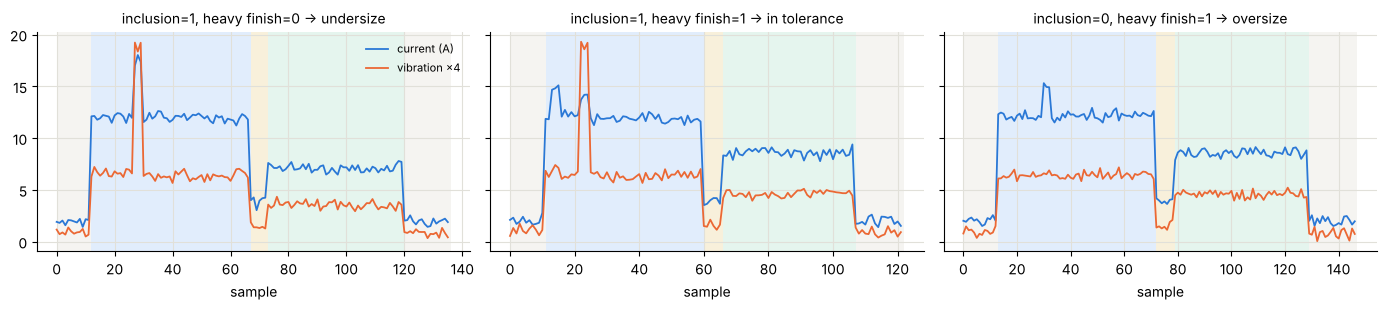

In [3]:
fig, axs = plt.subplots(1, 3, figsize=(14, 3.2), sharey=True)
shown = {}
for d in dtr:
    key = (d[3], d[4])
    if key not in shown and len(shown) < 3 and key != (0, 0): shown[key] = d
for ax, ((chip, heavy), d) in zip(axs, shown.items()):
    X, b = d[0], d[5]["bounds"]
    for k in range(5): ax.axvspan(b[k], b[k+1], color=["#efeee9", "#cde2fb", "#f4e7c4", "#d5efe3", "#efeee9"][k], alpha=.6, lw=0)
    ax.plot(X[:, 0], color=BLUE, lw=1.3, label="current (A)"); ax.plot(X[:, 1] * 4, color=ORANGE, lw=1.3, label="vibration ×4")
    ax.set_title(f"inclusion={chip}, heavy finish={heavy} → {CLASSES[d[2]]}", fontsize=10); ax.set_xlabel("sample")
axs[0].legend(fontsize=8); plt.tight_layout(); plt.show()

## 2. Why attention? The recurrent bottleneck

An RNN reads the cycle one sample at a time and must carry the inclusion forward in its hidden state
for ~100 steps. Last week this needed an LSTM *and* a forget-gate bias trick. The **path length**
between the cause and the decision grows with the distance between them.

The original attention mechanism (Bahdanau, Cho & Bengio, 2015) kept the RNN but let the decoder look back
at **all** encoder hidden states $h^{(1)},\dots,h^{(T)}$ through a weighted sum
$c_i = \sum_j \alpha_{ij} h^{(j)}$ with weights $\alpha_{ij}$ from a softmax. That gives a path of length one.

The transformer (Vaswani et al., 2017) keeps only that idea and drops the recurrence: every position
computes its output as an attention-weighted combination of every other position. Two consequences
we will measure today: long dependencies become easy, and all positions are processed **in parallel**.

## 3. Self-attention with no learned parameters

First turn the cycle into **tokens**. A token here is a 10-sample **patch**: 10 samples × 9 features =
a 90-dimensional vector (§9 explains the choice). A 140-sample cycle becomes 14 tokens.

The simplest self-attention (book, "Starting with a basic form of self-attention"):

$$\omega_{ij} = x^{(i)\top} x^{(j)}, \qquad \alpha_{ij} = \frac{\exp(\omega_{ij})}{\sum_k \exp(\omega_{ik})}, \qquad z^{(i)} = \sum_j \alpha_{ij}\, x^{(j)}$$

Every output $z^{(i)}$ is a weighted average of all inputs; the weights in each row sum to 1.

tokens: 14 | rows sum to 1.0
loop vs matrix, max |diff|: 2.384185791015625e-07


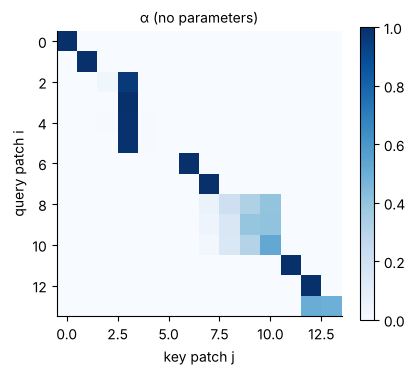

In [4]:
x0 = tr[0][0].reshape(15, 90)                 # one cycle, cut into 15 patches of 10 samples x 9 features
n0 = int((tr[1][0] + 9) // 10)                # patches that contain real samples
xb = x0[:n0]

omega = xb @ xb.T                              # (n0, n0) dot-product similarities
alpha = torch.softmax(omega, dim=1)            # normalise each row
z = alpha @ xb                                 # matrix form

z_loop = torch.stack([sum(alpha[i, j] * xb[j] for j in range(n0)) for i in range(n0)])   # explicit loop
print("tokens:", n0, "| rows sum to", alpha.sum(1).mean().item())
print("loop vs matrix, max |diff|:", (z - z_loop).abs().max().item())

plt.figure(figsize=(4.6, 3.8)); plt.imshow(alpha, cmap="Blues", vmin=0, vmax=1); plt.colorbar()
plt.xlabel("key patch j"); plt.ylabel("query patch i"); plt.title("α (no parameters)", fontsize=10); plt.grid(False); plt.show()

**Read the map.** Patches in the same machining phase attend to each other, so phase structure appears
without any training. But notice the failure mode: raw dot products favour **large-norm** tokens. In
this cycle several rough-cut patches put almost all their weight on the one patch containing the
current spike. Similarity should not be decided by magnitude alone — which is why the next step adds
learned projections.

## 4. Scaled dot-product attention: queries, keys and values

Give each token three roles through learned matrices:

$$q^{(i)} = W_q x^{(i)}, \quad k^{(i)} = W_k x^{(i)}, \quad v^{(i)} = W_v x^{(i)}, \qquad
\alpha_{ij} = \mathrm{softmax}_j\!\left(\frac{q^{(i)\top} k^{(j)}}{\sqrt{d_k}}\right), \quad z^{(i)} = \sum_j \alpha_{ij} v^{(j)}$$

The **query** is "what am I looking for", the **key** is "what do I contain", the **value** is "what I
hand over if selected" — terms borrowed from information retrieval. In matrix form:
$Z = \mathrm{softmax}(QK^\top/\sqrt{d_k})\,V$.

**Why divide by $\sqrt{d_k}$?** If the entries of $q$ and $k$ have unit variance, $q^\top k$ is a sum of
$d_k$ terms, so its standard deviation is $\sqrt{d_k}$. Large scores push the softmax towards a one-hot
argmax, and a saturated softmax passes back almost no gradient. Measure it:

In [5]:
g = torch.Generator().manual_seed(7); rows = []
for dk in [4, 16, 64, 256, 1024]:
    q = torch.randn(2000, dk, generator=g); k = torch.randn(2000, 15, dk, generator=g)
    s = torch.einsum("nd,ntd->nt", q, k)                     # 2000 queries x 15 keys
    for scaled in [False, True]:
        ss = (s / dk ** 0.5 if scaled else s).clone().requires_grad_(True)
        a = torch.softmax(ss, 1)
        (a * torch.randn(a.shape, generator=g)).sum().backward()   # any smooth downstream loss
        rows.append((dk, scaled, ss.detach().std().item(), a.detach().max(1).values.mean().item(),
                     ss.grad.norm(dim=1).mean().item()))
print(f"{'d_k':>5} {'scaled':>7} {'score std':>10} {'max weight':>11} {'grad norm':>10}")
for r in rows: print(f"{r[0]:>5} {str(r[1]):>7} {r[2]:>10.2f} {r[3]:>11.3f} {r[4]:>10.3f}")

  d_k  scaled  score std  max weight  grad norm
    4   False       1.99       0.436      0.292
    4    True       1.00       0.244      0.285
   16   False       4.02       0.694      0.237
   16    True       1.00       0.253      0.289
   64   False       8.00       0.838      0.154
   64    True       1.00       0.253      0.287
  256   False      15.86       0.919      0.086
  256    True       0.99       0.252      0.291
 1024   False      32.22       0.967      0.035
 1024    True       1.01       0.260      0.294


Unscaled, the score standard deviation tracks $\sqrt{d_k}$ (2, 4, 8, 16, 32), the largest weight climbs
towards 1, and the gradient that reaches the scores collapses about 8-fold by $d_k = 1024$. Scaled,
all three stay flat. The scaling factor is not cosmetic; it is what keeps attention trainable at
realistic widths.

## 5. Multi-head attention, by hand

One attention pattern per layer is limiting: the classifier may need to look at the inclusion *and*
at the finish-phase load at the same time. **Multi-head attention** runs $h$ attentions in parallel,
each in a $d_{model}/h$-dimensional subspace, then concatenates and mixes them with $W_O$:

$$\mathrm{MHA}(X) = [\,\mathrm{head}_1;\dots;\mathrm{head}_h\,]\,W_O, \qquad \mathrm{head}_i = \mathrm{softmax}\!\left(\frac{XW_q^{(i)}(XW_k^{(i)})^\top}{\sqrt{d_k}}\right) XW_v^{(i)}$$

With $d_{model}=32$ and $h=4$, each head works in 8 dimensions, so the cost is the same as one 32-wide head.
We implement it by hand using the weights of PyTorch's own module and check that the outputs agree.

In [6]:
torch.manual_seed(7)
d, h = 32, 4; dh = d // h
mha = nn.MultiheadAttention(d, h, batch_first=True)
xx = torch.randn(1, 16, d)                                       # 16 tokens ([CLS] + 15 patches)

Wq, Wk, Wv = mha.in_proj_weight.split(d); bq, bk, bv = mha.in_proj_bias.split(d)
Q, K, V = xx @ Wq.T + bq, xx @ Wk.T + bk, xx @ Wv.T + bv
heads = []
for i in range(h):
    sl = slice(i * dh, (i + 1) * dh)                             # head i owns 8 of the 32 dims
    A = torch.softmax(Q[..., sl] @ K[..., sl].transpose(1, 2) / dh ** 0.5, dim=-1)
    heads.append(A @ V[..., sl])
out_manual = torch.cat(heads, -1) @ mha.out_proj.weight.T + mha.out_proj.bias

out_torch, _ = mha(xx, xx, xx)
print("max |manual - nn.MultiheadAttention|:", (out_manual - out_torch).abs().max().item())
print("parameters in one MHA layer:", sum(p.numel() for p in mha.parameters()), "(= 4·32·32 weights + 4·32 biases)")

max |manual - nn.MultiheadAttention|: 8.940696716308594e-08
parameters in one MHA layer: 4224 (= 4·32·32 weights + 4·32 biases)


The difference is at float32 round-off level: the module does nothing more than the ten lines above.

## 6. The transformer block, masking and normalisation

A block wraps attention with three more ingredients:

* a **position-wise feed-forward network** (here 32 → 64 → 32) applied to each token separately;
* **residual connections** around both sub-layers, so each block learns a correction to its input;
* **Layer normalisation**, which normalises each token over its features. Batch norm normalises each
  feature over the batch — awkward for variable-length, padded sequences and for batch size 1 at inference.

| | Post-LN (original 2017) | Pre-LN (GPT-2 onwards, most modern models) |
|---|---|---|
| order | $x \leftarrow \mathrm{LN}(x + \mathrm{Sublayer}(x))$ | $x \leftarrow x + \mathrm{Sublayer}(\mathrm{LN}(x))$ |
| training | needs learning-rate warm-up; deep stacks are fragile | stable without warm-up; the residual path is untouched |
| in PyTorch | `norm_first=False` (default) | `norm_first=True` (used below) |

The **decoder** of the original transformer uses *masked* self-attention so that position $i$ cannot
read positions $j>i$ — otherwise next-token prediction would be trivially solved by copying. It also has
a cross-attention layer reading the encoder's output. Check that the mask really stops the future leaking:

In [7]:
torch.manual_seed(7)
layer = nn.TransformerEncoderLayer(32, 4, 64, dropout=0.0, batch_first=True, norm_first=True).eval()
xa = torch.randn(1, 15, 32)
xb2 = xa.clone(); xb2[:, 10:] += torch.randn(1, 5, 32) * 3      # change only tokens 10..14
cm = nn.Transformer.generate_square_subsequent_mask(15)          # -inf above the diagonal
with torch.no_grad():
    nomask = (layer(xa)[:, :10] - layer(xb2)[:, :10]).abs().max().item()
    withmask = (layer(xa, src_mask=cm, is_causal=True)[:, :10]
                - layer(xb2, src_mask=cm, is_causal=True)[:, :10]).abs().max().item()
print(f"outputs at positions 0-9 change by {nomask:.3f} without a mask, {withmask:.1f} with a causal mask")
print(cm[:4, :4])

outputs at positions 0-9 change by 0.273 without a mask, 0.0 with a causal mask
tensor([[0., -inf, -inf, -inf],
        [0., 0., -inf, -inf],
        [0., 0., 0., -inf],
        [0., 0., 0., 0.]])


## 7. The model: a patch transformer for machine cycles

Putting it together (a small encoder in the spirit of BERT and of PatchTST for time series):

1. cut the padded cycle into 15 patches of 10 samples × 9 features and project each to $d=32$;
2. prepend a learned **[CLS]** token whose final state is used for classification (as in BERT);
3. add a learned **positional embedding**;
4. two Pre-LN encoder blocks with 4 heads; a **key-padding mask** hides patches past the end of the cycle;
5. a linear head on [CLS].

`mask_tok` lets us blank out chosen patches — used later for pre-training and for occlusion.

In [8]:
class PatchTransformer(nn.Module):
    def __init__(self, d=32, heads=4, layers=2, ff=64, use_pos=True, n_cls=3, drop=0.1, pool="cls", patch=PATCH):
        super().__init__()
        self.patch = patch; self.n_tok = T_MAX // patch
        self.embed = nn.Linear(patch * 9, d)
        self.cls = nn.Parameter(torch.zeros(1, 1, d))
        self.pos = nn.Parameter(torch.randn(1, self.n_tok + 1, d) * 0.02) if use_pos else None
        layer = nn.TransformerEncoderLayer(d, heads, ff, drop, batch_first=True, norm_first=True)
        self.encoder = nn.TransformerEncoder(layer, layers, enable_nested_tensor=False)
        self.norm = nn.LayerNorm(d)
        self.pool = pool
        self.head = nn.Linear(2 * d if pool == "meanmax" else d, n_cls)
        self.recon = nn.Linear(d, patch * 9)            # only used for masked-patch pre-training

    def tokens(self, x, lengths, mask_tok=None):
        B = x.shape[0]
        z = self.embed(x.reshape(B, self.n_tok, self.patch * 9))
        if mask_tok is not None:
            z = z.masked_fill(mask_tok.unsqueeze(-1), 0.0)
        z = torch.cat([self.cls.expand(B, -1, -1), z], 1)
        if self.pos is not None:
            z = z + self.pos
        n_valid = (lengths + self.patch - 1) // self.patch
        pad = torch.arange(self.n_tok + 1).unsqueeze(0) > n_valid.unsqueeze(1)   # True = ignore
        return z, pad

    def forward(self, x, lengths, mask_tok=None, return_tokens=False):
        z, pad = self.tokens(x, lengths, mask_tok)
        h = self.norm(self.encoder(z, src_key_padding_mask=pad))
        if return_tokens:
            return h, pad
        if self.pool == "meanmax":
            return self.head(pool_meanmax(h, pad))
        return self.head(h[:, 0])

def pool_meanmax(h, pad):
    '''Mean and max over the valid patch tokens (skip [CLS]) -> (B, 2d).'''
    h, v = h[:, 1:], ~pad[:, 1:]
    hmax = h.masked_fill(~v.unsqueeze(-1), -1e9).max(1).values
    hmean = (h * v.unsqueeze(-1)).sum(1) / v.sum(1, keepdim=True)
    return torch.cat([hmean, hmax], 1)

class LSTMClassifier(nn.Module):
    '''Last week's best model: LSTM with the forget gate initialised open.'''
    def __init__(self, hidden=48):
        super().__init__()
        self.lstm = nn.LSTM(9, hidden, batch_first=True)
        self.lstm.bias_ih_l0.data[hidden:2 * hidden] = 2.0
        self.head = nn.Sequential(nn.Linear(hidden, 32), nn.ReLU(), nn.Linear(32, 3))
    def forward(self, x, lengths):
        p = nn.utils.rnn.pack_padded_sequence(x, lengths, batch_first=True, enforce_sorted=False)
        _, (h, _) = self.lstm(p)
        return self.head(h[-1])

@torch.no_grad()
def acc(model, X, L, y):
    model.eval(); return (model(X, L).argmax(1) == y).float().mean().item()

def fit(model, Xtr, Ltr, ytr, Xva, Lva, yva, epochs, lr=2e-3, bs=64, seed=0):
    torch.manual_seed(seed)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, epochs)
    hist = []
    for ep in range(epochs):
        model.train(); perm = torch.randperm(len(ytr))
        for i in range(0, len(perm), bs):
            idx = perm[i:i + bs]
            loss = F.cross_entropy(model(Xtr[idx], Ltr[idx]), ytr[idx])
            opt.zero_grad(); loss.backward(); nn.utils.clip_grad_norm_(model.parameters(), 1.0); opt.step()
        sched.step(); hist.append(acc(model, Xva, Lva, yva))
    return hist

nparams = lambda m: sum(p.numel() for p in m.parameters())
print("PatchTransformer parameters:", nparams(PatchTransformer()))

PatchTransformer parameters: 23677


## 8. Project: transformer vs. last week's LSTM

Same data, same splits, 30 epochs each, Adam with a cosine schedule and gradient clipping. We also
train the transformer **without** positional embeddings — keep that result in mind for §9.

transformer       params  23677 | test acc 0.993 |   7.1 s | first epoch ≥95% valid: 7


transformer_noPE  params  23165 | test acc 0.993 |   5.7 s | first epoch ≥95% valid: 7


lstm              params  12995 | test acc 0.993 |  60.1 s | first epoch ≥95% valid: 10

wall-time ratio LSTM / transformer: 8.5x


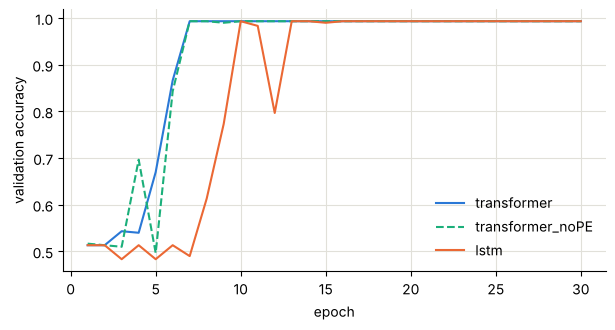

In [9]:
EPOCHS = 30; results, hists, models = {}, {}, {}
for name, ctor, lr in [("transformer", lambda: PatchTransformer(), 2e-3),
                       ("transformer_noPE", lambda: PatchTransformer(use_pos=False), 2e-3),
                       ("lstm", lambda: LSTMClassifier(), 3e-3)]:
    torch.manual_seed(0); m = ctor(); t = time.time()
    hists[name] = fit(m, *tr, *va, EPOCHS, lr=lr); secs = time.time() - t
    first = next((i + 1 for i, a in enumerate(hists[name]) if a >= 0.95), None)
    results[name] = dict(params=nparams(m), test=acc(m, *te), secs=secs, epochs_to_95=first); models[name] = m
    print(f"{name:17s} params {nparams(m):6d} | test acc {results[name]['test']:.3f} | "
          f"{secs:5.1f} s | first epoch ≥95% valid: {first}")
print(f"\nwall-time ratio LSTM / transformer: {results['lstm']['secs'] / results['transformer']['secs']:.1f}x")

plt.figure(figsize=(7, 3.4))
for k, c, ls in [("transformer", BLUE, "-"), ("transformer_noPE", AQUA, "--"), ("lstm", ORANGE, "-")]:
    plt.plot(range(1, EPOCHS + 1), hists[k], color=c, ls=ls, label=k)
plt.xlabel("epoch"); plt.ylabel("validation accuracy"); plt.legend(); plt.show()

In [10]:
tf = models["transformer"].eval()
with torch.no_grad(): pred = tf(te[0], te[1]).argmax(1).numpy()
cm_ = np.zeros((3, 3), int)
for a, b in zip(te[2].numpy(), pred): cm_[a, b] += 1
print("confusion matrix (rows = true, cols = predicted):", CLASSES); print(cm_)

confusion matrix (rows = true, cols = predicted): ['undersize', 'in tolerance', 'oversize']
[[147   0   0]
 [  1 294   3]
 [  0   0 155]]


**Reading the result.** Both models end at the same test accuracy — the LSTM is not a bad model once
its forget gate is opened. What differs is the *route*: the transformer connects the inclusion patch
to the decision in one attention step, and it processes all 16 tokens at once instead of 150
sequential steps, so the same 30 epochs take several times less wall time even on 2 CPU cores. On a GPU,
where parallel work is nearly free, that gap is the reason transformers replaced RNNs.

The remaining errors sit on the tolerance boundary: the $4\,\mu$m process noise occasionally pushes a
part across $\pm 12\,\mu$m, which no model can see in the signals.

## 9. Order: positional information

Self-attention is **permutation-equivariant**: shuffle the tokens and the outputs shuffle the same
way; the [CLS] summary does not change at all. Test it on the two trained models:

In [11]:
perm = torch.randperm(15, generator=torch.Generator().manual_seed(3))
full = te[1] == 150                                     # cycles that fill all 15 patches
xs = te[0][full].reshape(-1, 15, 90)[:, perm].reshape(-1, 150, 9)
with torch.no_grad():
    for k in ["transformer_noPE", "transformer"]:
        diff = (models[k](te[0][full], te[1][full]) - models[k](xs, te[1][full])).abs().max().item()
        print(f"{k:17s} max |Δ logit| after shuffling the patches of {int(full.sum())} cycles: {diff:.2e}")

transformer_noPE  max |Δ logit| after shuffling the patches of 15 cycles: 4.77e-07
transformer       max |Δ logit| after shuffling the patches of 15 cycles: 2.52e-01


Without positional embeddings the model literally cannot tell a shuffled cycle from the original
(the difference is float32 noise). So why did `transformer_noPE` still reach the same accuracy in §8?
Because for *this* label, **content already identifies position**: the op-code channel says which
phase each patch is in, and the inclusion is recognisable wherever it occurs. A bag of patches is
enough.

Now a task where order is the whole point. A data logger occasionally writes its ring buffer out of
order; can the model flag scrambled cycles?

In [12]:
def shuffled_task(T, seed):
    '''Label 1 = the cycle's patches were written out of order, 0 = intact.'''
    X, L, _ = T; g = torch.Generator().manual_seed(seed)
    X = X.clone(); y = torch.zeros(len(X), dtype=torch.long)
    for i in range(len(X)):
        if torch.rand(1, generator=g) < 0.5:
            n = int((L[i] + 9) // 10); p = torch.randperm(n, generator=g)
            X[i, :n * 10] = X[i, :n * 10].reshape(n, 10, 9)[p].reshape(n * 10, 9); y[i] = 1
    return X, L, y

otr, ova, ote = shuffled_task(tr, 1), shuffled_task(va, 2), shuffled_task(te, 3)
for pos in [False, True]:
    torch.manual_seed(0); m = PatchTransformer(use_pos=pos, n_cls=2)
    fit(m, *otr, *ova, 20, lr=2e-3)
    print(f"scrambled-buffer detection, positional embedding={pos}: test accuracy {acc(m, *ote):.3f}")

scrambled-buffer detection, positional embedding=False: test accuracy 0.515


scrambled-buffer detection, positional embedding=True: test accuracy 0.998


Chance versus near-perfect. **Options for injecting position:**

| method | how | used by |
|---|---|---|
| sinusoidal (absolute) | add $\sin(p/10000^{2i/d}),\ \cos(p/10000^{2i/d})$ to the embedding | original transformer |
| learned (absolute) | a trainable vector per position (used here) | BERT, GPT-2, ViT |
| **rotary (RoPE, relative)** | rotate $q$ and $k$ by a position-dependent angle so $q^\top k$ depends on $i-j$ | most current open LLMs (e.g. Llama) |
| ALiBi (relative) | subtract a distance-proportional bias from the scores | some long-context models |

Relative schemes generalise better to sequences longer than those seen in training — relevant if your
machine sometimes runs longer cycles.

## 10. Tokenising a signal: patching and the cost of attention

Attention compares every token with every other token, so cost and memory grow with the **square** of
the sequence length. Treating each 50 Hz sample as a token gives 151 tokens (with [CLS]) and
22 801 scores per head per layer. **Patching** — grouping consecutive samples into one token, as in
PatchTST (Nie et al., 2023) and the Vision Transformer's image patches — cuts this sharply.

In [13]:
for p in [1, 5, 10, 25]:
    torch.manual_seed(0); m = PatchTransformer(patch=p)
    t = time.time(); fit(m, *tr, *va, 20, lr=2e-3); secs = time.time() - t
    n_tok = 150 // p + 1
    print(f"patch {p:2d}: {n_tok:3d} tokens, {n_tok**2:6d} scores/head, 20 epochs in {secs:5.1f} s, test acc {acc(m, *te):.3f}")

patch  1: 151 tokens,  22801 scores/head, 20 epochs in  76.7 s, test acc 0.993


patch  5:  31 tokens,    961 scores/head, 20 epochs in  12.8 s, test acc 0.993


patch 10:  16 tokens,    256 scores/head, 20 epochs in   3.8 s, test acc 0.993


patch 25:   7 tokens,     49 scores/head, 20 epochs in   8.2 s, test acc 0.993


Same accuracy for every patch size on this task; patch 10 trains roughly 20× faster than patch 1. In
practice, choose the patch so one token covers the shortest event you care about (the inclusion lasts
3 samples, so it lands in one or at most two 10-sample patches) and the token count stays in the hundreds. Patching
also gives each token local context — a single sample is a poor "word".

## 11. From the original transformer to today's language models

The chapter's second half surveys models built from transformer blocks. They differ mainly in **which
attention mask** they use and **what they are pre-trained to predict**:

| family | mask | pre-training task | examples | typical use |
|---|---|---|---|---|
| encoder-only | full (bidirectional) | masked-token prediction | BERT, RoBERTa, DistilBERT | classification, tagging, embeddings / search |
| decoder-only | causal | next-token prediction | GPT series, Llama, Mistral, Claude | generation, chat, few-shot and zero-shot tasks |
| encoder–decoder | full in encoder, causal in decoder + cross-attention | denoising / span corruption | T5, BART, Whisper | translation, summarisation, speech-to-text |

**What has changed since the book (2022), in brief** — check current documentation, as this field moves quickly:

* **Decoder-only models dominate** general-purpose language work; scale plus instruction tuning and
  reinforcement learning from human feedback turned next-token predictors into assistants.
* **Architecture details** converged: Pre-LN (often RMSNorm), rotary position embeddings, SwiGLU
  feed-forward layers, grouped-query attention to shrink the key/value cache.
* **FlashAttention** computes exact attention in tiles that fit on-chip memory — same result, much less
  memory traffic — enabling long contexts.
* **Parameter-efficient fine-tuning** (LoRA and relatives) adapts a frozen model by training small
  low-rank update matrices, so adapting a large model fits on one GPU.
* Pinned library versions from the book (e.g. `transformers==4.9.1`) are long outdated; the high-level
  `AutoTokenizer` / `AutoModel...` / `Trainer` APIs remain the standard entry point.
* BERT's next-sentence prediction task was dropped by later encoders (RoBERTa found it unnecessary).

The common thread for engineers: **pre-train once on plentiful unlabeled data, adapt cheaply to a task
with few labels.** Next we do exactly that on machine cycles.

## 12. Pre-training on unlabeled cycles, then learning from few labels

On a real line, every part produces a signal but only a few are measured on a CMM. We simulate
**4 000 unlabeled cycles** and pre-train the encoder by **masked-patch reconstruction** — the time-series
analogue of BERT's masked-language modelling: blank out 40 % of the patches and predict their raw values
from the rest.

One design detail matters a lot, and we will measure it: the loss is computed on the masked patches
**and** (with weight 1) on the visible ones. With masked-only loss the encoder is never asked to keep a
rare, unpredictable event like the inclusion in its own token.

In [14]:
un = to_tensors(make_dataset(4000, 999))

def pretrain(model, X, L, epochs, mask_frac=0.4, w_visible=1.0, lr=2e-3, bs=128, seed=0):
    torch.manual_seed(seed); opt = torch.optim.AdamW(model.parameters(), lr=lr)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, epochs); losses = []
    for ep in range(epochs):
        model.train(); perm = torch.randperm(len(X)); tot = 0
        for i in range(0, len(perm), bs):
            idx = perm[i:i + bs]; x, l = X[idx], L[idx]
            valid = torch.arange(15).unsqueeze(0) < ((l + 9) // 10).unsqueeze(1)
            msk = (torch.rand(len(idx), 15) < mask_frac) & valid
            hh, _ = model(x, l, mask_tok=msk, return_tokens=True)
            err = ((model.recon(hh[:, 1:]) - x.reshape(len(idx), 15, 90)) ** 2).mean(-1)
            loss = err[msk].mean() + w_visible * err[valid & ~msk].mean()
            opt.zero_grad(); loss.backward(); nn.utils.clip_grad_norm_(model.parameters(), 1.0); opt.step()
            tot += loss.item() * len(idx)
        sched.step(); losses.append(tot / len(X))
    return losses

t = time.time()
torch.manual_seed(0); pre = PatchTransformer(); pre_loss = pretrain(pre, un[0], un[1], 30)
print(f"pre-training: loss {pre_loss[0]:.3f} -> {pre_loss[-1]:.3f} in {time.time() - t:.0f} s")
torch.manual_seed(0); pre_masked_only = PatchTransformer()
_ = pretrain(pre_masked_only, un[0], un[1], 30, w_visible=0.0)
torch.manual_seed(0); rand = PatchTransformer()          # untrained control: same architecture

pre-training: loss 0.712 -> 0.071 in 27 s


**Adapting.** The book describes two strategies: *feature-based* (freeze the pre-trained model, train a
small classifier on its outputs) and *fine-tuning* (update everything). With only tens of labels the
feature-based route is the safe one, so we freeze the encoder, pool its patch outputs (mean and max),
and fit a logistic regression. Controls: the same probe on a **random** encoder, and a transformer
trained from scratch on the same few labels.

In [15]:
@torch.no_grad()
def features(model, X, L):
    model.eval(); hh, pad = model(X, L, return_tokens=True)
    return pool_meanmax(hh, pad).numpy()

FE = {k: (features(m, *tr[:2]), features(m, *te[:2]))
      for k, m in [("pretrained", pre), ("random", rand), ("masked_only", pre_masked_only)]}
ytr_np, yte_np = tr[2].numpy(), te[2].numpy()
NS = [24, 48, 96, 192, 800]
curve = {"pretrained_probe": [], "random_probe": [], "masked_only_probe": [], "scratch": []}
for n in NS:
    seeds = range(5) if n < 800 else range(1)
    for key, fe in [("pretrained_probe", "pretrained"), ("random_probe", "random"), ("masked_only_probe", "masked_only")]:
        r = []
        for s in seeds:
            idx = torch.randperm(800, generator=torch.Generator().manual_seed(s))[:n].numpy()
            clf = make_pipeline(StandardScaler(), LogisticRegression(C=1.0, max_iter=3000))
            clf.fit(FE[fe][0][idx], ytr_np[idx]); r.append(clf.score(FE[fe][1], yte_np))
        curve[key].append(np.mean(r))
    if n == 800:
        curve["scratch"].append(results["transformer"]["test"])
    else:
        r = []
        for s in range(3):
            idx = torch.randperm(800, generator=torch.Generator().manual_seed(s))[:n]
            torch.manual_seed(s); m = PatchTransformer()
            fit(m, tr[0][idx], tr[1][idx], tr[2][idx], *va, 60, lr=2e-3, bs=16, seed=s)
            r.append(acc(m, *te))
        curve["scratch"].append(np.mean(r))
print(f"{'labels':>6} " + " ".join(f"{k:>18}" for k in curve))
for i, n in enumerate(NS): print(f"{n:>6} " + " ".join(f"{curve[k][i]:>18.3f}" for k in curve))

labels   pretrained_probe       random_probe  masked_only_probe            scratch
    24              0.610              0.572              0.532              0.497
    48              0.789              0.651              0.598              0.693
    96              0.921              0.754              0.686              0.814
   192              0.979              0.839              0.762              0.986
   800              0.992              0.950              0.848              0.993


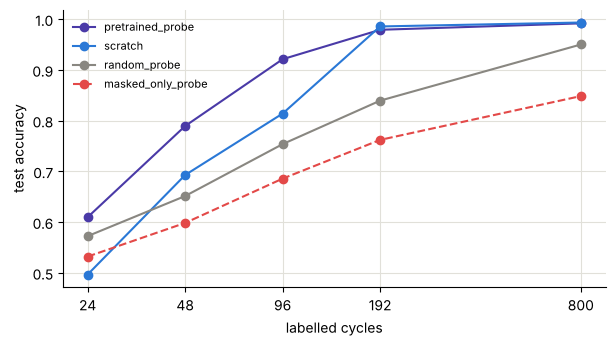

In [16]:
plt.figure(figsize=(7, 3.6))
for k, c, ls in [("pretrained_probe", VIOLET, "-"), ("scratch", BLUE, "-"), ("random_probe", MUTED, "-"), ("masked_only_probe", RED, "--")]:
    plt.plot(NS, curve[k], "o", color=c, ls=ls, label=k)
plt.xscale("log"); plt.xticks(NS, [str(v) for v in NS]); plt.minorticks_off()
plt.xlabel("labelled cycles"); plt.ylabel("test accuracy"); plt.legend(fontsize=8); plt.show()

**What the curve says.**

* With 48–96 labels, the frozen pre-trained encoder beats both training from scratch and the random
  encoder by a wide margin: the unlabeled cycles taught it what a normal cycle looks like, so an
  inclusion or a heavy finish stands out in its features.
* By 192 labels, training from scratch catches up. Pre-training buys **label efficiency**, not a
  higher ceiling — the gap closes as labels become plentiful.
* The **masked-only** objective is *worse than a random encoder*. The pre-training task decides what
  the representation keeps; an objective that never rewards remembering the rare event throws it away.
  This is the most transferable lesson of the section: choose the self-supervised task with the
  downstream signal in mind.

## 13. Using a pre-trained language model in practice

For **text** — maintenance logs, operator shift notes, non-conformance reports — you would not pre-train
yourself; you download an encoder such as DistilBERT and fine-tune it. The recipe below is the modern
equivalent of the chapter's IMDb example. It needs internet access to the Hugging Face Hub and is
therefore **not executed here**; run it on your own machine (`pip install transformers datasets peft`).

```python
from transformers import AutoTokenizer, AutoModelForSequenceClassification, TrainingArguments, Trainer
from datasets import Dataset

logs = {"text": ["Spindle vibration alarm during roughing, insert chipped",
                 "Coolant pressure low, refilled tank",
                 "Axis 3 servo overcurrent on robot cell B, reset after inspection"],
        "label": [0, 1, 2]}                       # tool damage / coolant / drive fault  (use hundreds)
ds = Dataset.from_dict(logs).train_test_split(test_size=0.2, seed=0)

name = "distilbert-base-uncased"
tok = AutoTokenizer.from_pretrained(name)
ds = ds.map(lambda b: tok(b["text"], truncation=True, padding="max_length", max_length=64), batched=True)
model = AutoModelForSequenceClassification.from_pretrained(name, num_labels=3)

# Optional: parameter-efficient fine-tuning with LoRA (trains ~1% of the weights)
# from peft import LoraConfig, get_peft_model
# model = get_peft_model(model, LoraConfig(task_type="SEQ_CLS", r=8, lora_alpha=16,
#                                          target_modules=["q_lin", "v_lin"]))

args = TrainingArguments("log-classifier", num_train_epochs=3, learning_rate=5e-5,
                         per_device_train_batch_size=16, eval_strategy="epoch")
Trainer(model=model, args=args, train_dataset=ds["train"], eval_dataset=ds["test"]).train()
```

The structure is the same as §12: a pre-trained encoder, a small classification head on the [CLS]
position, and a short adaptation run.

## 14. Attention as explanation — handle with care

Attention weights are tempting to read as "what the model looked at". Let's check that against
**occlusion**: blank one patch and measure how much the probability of the true class drops.

In [17]:
@torch.no_grad()
def cls_attention(model, X, L):
    '''Last-layer attention from [CLS] to each patch, averaged over heads.'''
    z, pad = model.tokens(X, L)
    for li, lay in enumerate(model.encoder.layers):
        if li == len(model.encoder.layers) - 1:
            xn = lay.norm1(z)
            _, w = lay.self_attn(xn, xn, xn, key_padding_mask=pad, need_weights=True, average_attn_weights=True)
        z = lay(z, src_key_padding_mask=pad)
    return w[:, 0, 1:]

@torch.no_grad()
def occlusion(model, X, L, y):
    base = torch.softmax(model(X, L), 1)[torch.arange(len(y)), y]
    out = torch.zeros(len(y), 15)
    for j in range(15):
        mk = torch.zeros(len(y), 15, dtype=torch.bool); mk[:, j] = True
        out[:, j] = base - torch.softmax(model(X, L, mask_tok=mk), 1)[torch.arange(len(y)), y]
    return out

att, occ = cls_attention(tf, te[0], te[1]), occlusion(tf, te[0], te[1], te[2])
cat = {"inclusion": ([], []), "coolant surge": ([], []), "finish": ([], []), "other": ([], [])}
for i, (X, op, yy, chip, heavy, meta) in enumerate(dte):
    n = (len(X) + 9) // 10
    pc = (meta["t_chip"] + 1) // 10 if chip else -1                 # patch holding the spike's middle
    ps_ = {s // 10 for s in meta["surges"]} | {(s + 2) // 10 for s in meta["surges"]}
    fin = set(range(meta["bounds"][3] // 10 + 1, meta["bounds"][4] // 10))
    for j in range(n):
        k = "inclusion" if j == pc else ("coolant surge" if j in ps_ else ("finish" if j in fin else "other"))
        cat[k][0].append(att[i, j].item()); cat[k][1].append(occ[i, j].item())
print(f"uniform attention would be ≈ {np.mean([1 / ((len(d[0]) + 9) // 10) for d in dte]):.3f}\n")
print(f"{'patch type':>14} {'n':>5} {'mean attention':>15} {'mean occlusion drop':>20}")
for k, (a, o) in cat.items(): print(f"{k:>14} {len(a):>5} {np.mean(a):>15.3f} {np.mean(o):>20.4f}")

uniform attention would be ≈ 0.075

    patch type     n  mean attention  mean occlusion drop
     inclusion   295           0.363               0.8224
 coolant surge  1240           0.067               0.0030
        finish  1553           0.079              -0.0001
         other  4949           0.051               0.0016


The inclusion patch gets both high attention and a large occlusion effect — attention and importance
agree there. The finish patches look *unimportant* to both methods. But the finish load decides between
in-tolerance and oversize, so it must matter. Occlude **all** finish patches together:

In [18]:
grp = {0: [], 1: []}
with torch.no_grad():
    for i, (X, op, yy, chip, heavy, meta) in enumerate(dte):
        bd = meta["bounds"]; mk = torch.zeros(1, 15, dtype=torch.bool)
        mk[0, bd[3] // 10:(bd[4] + 9) // 10] = True
        p0 = torch.softmax(tf(te[0][i:i+1], te[1][i:i+1]), 1)[0, yy]
        p1 = torch.softmax(tf(te[0][i:i+1], te[1][i:i+1], mask_tok=mk), 1)[0, yy]
        grp[heavy].append((p0 - p1).item())
print(f"occlude every finish patch -> drop in p(true class): light finish {np.mean(grp[0]):.3f}, heavy finish {np.mean(grp[1]):.3f}")

occlude every finish patch -> drop in p(true class): light finish 0.986, heavy finish 0.004


Two lessons an engineer should carry into any model review:

1. **Redundancy hides importance.** The finish load is spread over four or five patches; removing one changes
   nothing because the other four still carry it. Neither single-patch attention nor single-patch
   occlusion can see it. Remove the group and the light-finish parts collapse.
2. **The model learned an asymmetric rule.** Hiding the finish pass hurts only the *light*-finish parts:
   the model treats "light finish visible" as the evidence and defaults to "heavy" when the finish is
   missing. That is a fact about this model that no attention map shows.

Attention weights describe how information was **routed** in one layer; they are not an attribution
method. Use them to form hypotheses, and confirm with interventions (occlusion, ablation, counterfactual
cycles) — the same habit as the late-window ablation in the Chapter 15 notebook.

## 15. Protocol — what to remember

1. **Tokenise deliberately.** For signals, patch so one token covers the shortest event of interest and the token count stays modest; attention cost grows with its square.
2. **Scale the scores** by $1/\sqrt{d_k}$ — it keeps the softmax out of saturation.
3. **Use Pre-LN** (`norm_first=True`), residuals, LayerNorm, and a key-padding mask for ragged sequences.
4. **Give the model position** when order matters — and test whether it does (shuffle the tokens).
5. **Mask the future** in anything that predicts forward in time; check that changing the future leaves past outputs untouched.
6. **Pre-train on the unlabeled data you already log**, choosing an objective that keeps the rare events you care about; with few labels, freeze and probe before fine-tuning.
7. **Compare against the strong baseline** (here, the open-gate LSTM) on accuracy *and* cost.
8. **Do not read attention as importance**; verify with occlusion, including group occlusion.

## 16. Exercises

1. **Sinusoidal vs. learned positions.** Replace the learned positional embedding with the fixed sinusoidal one and repeat the scrambled-buffer task. Then train on cycles of length ≤ 130 and test on 140–150: which scheme copes better?
2. **Heads and layers.** Train with 1, 2, 4 and 8 heads (keeping $d=32$) and with 1–4 layers. Which matters more on this task, and how does the epoch-to-95 % change?
3. **Without the op code.** Remove the op-code one-hot features. Does `transformer_noPE` still match the version with positions on the diameter task? Explain using §9.
4. **Fine-tuning vs. probing.** Starting from the pre-trained encoder, fine-tune *all* weights with 96 and 192 labels (try learning rates $10^{-4}$ and $5\cdot10^{-4}$). When does fine-tuning beat the frozen probe? Try linear-probe-then-fine-tune.
5. **Mask ratio.** Repeat pre-training with mask fractions 0.15, 0.4 and 0.75. Plot probe accuracy at 48 labels against the mask fraction.
6. **Forecasting with a causal transformer.** Build a decoder-style model (causal mask) that predicts the next patch's mean spindle current from the patches so far. Verify with the §6 test that it cannot see the future.
7. **Long cycles.** Generate cycles of 1 000–1 500 samples with the inclusion at $t\approx 100$ and the finish near the end. Compare patch sizes 10 and 50 for accuracy, time and memory; what limits patch 1?
8. **Explanation audit.** For 20 misclassified or low-confidence test parts, show the [CLS] attention, single-patch occlusion and group occlusion side by side. Write a two-sentence diagnosis for each and say which method found the cause.

## 17. References

* Raschka, S., Liu, Y. & Mirjalili, V. (2022). *Machine Learning with PyTorch and Scikit-Learn*, ch. 16. Packt.
* Bahdanau, D., Cho, K. & Bengio, Y. (2015). Neural machine translation by jointly learning to align and translate. *ICLR*.
* Vaswani, A. et al. (2017). Attention is all you need. *NeurIPS*.
* Devlin, J., Chang, M.-W., Lee, K. & Toutanova, K. (2019). BERT: Pre-training of deep bidirectional transformers for language understanding. *NAACL*.
* Liu, Y. et al. (2019). RoBERTa: A robustly optimized BERT pretraining approach. *arXiv:1907.11692*.
* Radford, A. et al. (2019). Language models are unsupervised multitask learners. OpenAI technical report (GPT-2).
* Brown, T. et al. (2020). Language models are few-shot learners. *NeurIPS* (GPT-3).
* Lewis, M. et al. (2020). BART: Denoising sequence-to-sequence pre-training. *ACL*.
* Xiong, R. et al. (2020). On layer normalization in the transformer architecture. *ICML* (Pre-LN).
* Dosovitskiy, A. et al. (2021). An image is worth 16×16 words: Transformers for image recognition at scale. *ICLR*.
* Hu, E. et al. (2022). LoRA: Low-rank adaptation of large language models. *ICLR*.
* Dao, T. et al. (2022). FlashAttention: Fast and memory-efficient exact attention with IO-awareness. *NeurIPS*.
* He, K. et al. (2022). Masked autoencoders are scalable vision learners. *CVPR*.
* Nie, Y. et al. (2023). A time series is worth 64 words: Long-term forecasting with transformers (PatchTST). *ICLR*.
* Su, J. et al. (2024). RoFormer: Enhanced transformer with rotary position embedding. *Neurocomputing* 568.
* Jain, S. & Wallace, B. (2019). Attention is not explanation. *NAACL*; Wiegreffe, S. & Pinter, Y. (2019). Attention is not not explanation. *EMNLP*.
* PyTorch documentation: `torch.nn.MultiheadAttention`, `torch.nn.TransformerEncoderLayer`. Hugging Face Transformers documentation (`AutoModelForSequenceClassification`, `Trainer`).

Generated by Claude and customized by

<div align="center">
<img src="https://raw.githubusercontent.com/dewdotninja/sharing-github/refs/heads/master/dewninja_logo50.jpg" alt="dewninja"/>
</div>
<div align="center">dew.ninja 2026</div>